In [ ]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

from utils import analysis_utils

In [ ]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

In [ ]:
import networkx as nx

In [8]:
file_ids = list(range(0, 12+1))
# file_ids = [0,	# paper
#			 1,	# nice states
#			 2,	# nice manifold
#			 5,	# variety
#			 6,	# nice quiescence
#			 7,	# nice states
#			 9,	# nice heatmap
#			 11]   # variety

save = True

In [ ]:
for file_id in file_ids:
	filename, traces, behavior, states, timestamps, aux = analysis_utils.read_data('fly', file_id)

	# 1. Convert one-hot DataFrame to state indices
	state_labels = list(states.columns)
	# background_idx = state_labels.index('background')
	background_idx = np.empty((0,))

	# Convert one-hot to state index
	def onehot_to_index(df):
		return np.argmax(df.values, axis=1)

	state_seq = onehot_to_index(states)

	# 2. Remove 'background' by replacing with most recent non-background state
	state_seq_clean = state_seq.copy()
	N = len(state_seq_clean)

	# Find indices where state is background
	# bg_mask = (state_seq_clean == background_idx)
	bg_mask = np.empty((0,))

	# If the series starts with background, look forward for first non-background
	if False and bg_mask[0]:
		first_non_bg = np.argmax(~bg_mask)
		state_seq_clean[:first_non_bg] = state_seq_clean[first_non_bg]

	# For all other background entries, look back for most recent non-background
	# for i in range(1, N):
	#	 if state_seq_clean[i] == background_idx:
	#		 state_seq_clean[i] = state_seq_clean[i-1]

	# 3. Compute transition matrix (excluding self-transitions)
	num_states = len(state_labels)
	transitions = np.zeros((num_states, num_states), dtype=int)

	for t in range(N-1):
		from_state = state_seq_clean[t]
		to_state = state_seq_clean[t+1]
		if from_state != to_state:
			transitions[from_state, to_state] += 1

	# Remove background row and column for plotting
	# transitions_no_bg = transitions[1:, 1:]
	# labels_no_bg = state_labels[1:]
	transitions_no_bg = transitions
	labels_no_bg = state_labels

	# Normalize to relative frequencies
	row_sums = transitions_no_bg.sum(axis=1, keepdims=True)
	rel_transitions = transitions_no_bg / np.where(row_sums == 0, 1, row_sums)

	# 4. Plot heatmap
	plt.figure(figsize=(7, 6))
	sns.heatmap(
		rel_transitions,
		annot=True,
		fmt='.2f',
		cmap='Blues',
		xticklabels=labels_no_bg,
		yticklabels=labels_no_bg
	)
	plt.xlabel('To state')
	plt.ylabel('From state')
	plt.title('')
	plt.tight_layout()

	if save:
		os.makedirs('../../out/plots/state_transitions', exist_ok=True)
		plt.savefig(
			f'../../out/plots/state_transitions/{filename}_matrix.png',
			dpi=300,
			bbox_inches='tight'
		)

	plt.clf()
	plt.figure(figsize=(10, 10))

	# -----------------------------
	# Build graph
	# -----------------------------
	G = nx.DiGraph()
	G.add_nodes_from(labels_no_bg)

	for i, src in enumerate(labels_no_bg):
		for j, tgt in enumerate(labels_no_bg):
			w = float(rel_transitions[i, j])
			if i != j and w > 0:
				G.add_edge(src, tgt, weight=w)

	# Layout
	pos = nx.spring_layout(G, seed=42, k=2.5)

	# Draw nodes
	nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=500)

	# Draw node labels
	nx.draw_networkx_labels(G, pos, font_size=7)

	# Edge labels
	edge_labels = nx.get_edge_attributes(G, 'weight')
	formatted_labels = {edge: f'{label:.2f}' for edge, label in edge_labels.items()}

	# Assign unique colors
	import matplotlib.cm as cm
	import matplotlib.colors as mcolors

	edge_list = list(G.edges())
	cmap = cm.get_cmap('tab20', len(edge_list))
	edge_colors = {edge: mcolors.to_hex(cmap(i)) for i, edge in enumerate(edge_list)}

	# Linewidth scaling
	label_values = np.array(list(edge_labels.values()))
	min_val, max_val = label_values.min(), label_values.max()
	min_width, max_width = 1.0, 6.0

	def map_boldness(val):
		if max_val == min_val:
			return (min_width + max_width) / 2
		return min_width + (val - min_val) / (max_val - min_val) * (max_width - min_width)

	# Find antiparallel edges
	antiparallel_pairs = set()
	for (u, v) in G.edges():
		if (v, u) in G.edges() and (v, u) not in antiparallel_pairs:
			antiparallel_pairs.add((u, v))
			antiparallel_pairs.add((v, u))

	unique_pairs = set()
	for (u, v) in antiparallel_pairs:
		if (v, u) in antiparallel_pairs and u < v:
			unique_pairs.add((u, v))

	# Label placement
	label_offset = 0.15
	for (m, n) in unique_pairs:
		x0, y0 = pos[m]
		x1, y1 = pos[n]
		mx, my = (x0 + x1) / 2, (y0 + y1) / 2

		dx, dy = x1 - x0, y1 - y0
		perp = np.array([-dy, dx])
		perp_norm = perp / (np.linalg.norm(perp) + 1e-8)

		if (m, n) in formatted_labels:
			ox, oy = mx - label_offset * perp_norm[0], my - label_offset * perp_norm[1]
			plt.text(
				ox, oy, formatted_labels[(m, n)],
				ha='center', va='center', fontsize=8,
				bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
				color=edge_colors.get((m, n), 'k')
			)

		if (n, m) in formatted_labels:
			ox, oy = mx + label_offset * perp_norm[0], my + label_offset * perp_norm[1]
			plt.text(
				ox, oy, formatted_labels[(n, m)],
				ha='center', va='center', fontsize=8,
				bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
				color=edge_colors.get((n, m), 'k')
			)

	# Non-antiparallel edges
	for (u, v), label in formatted_labels.items():
		if ((u, v) not in antiparallel_pairs) and ((v, u) not in antiparallel_pairs):
			x0, y0 = pos[u]
			x1, y1 = pos[v]
			mx, my = (x0 + x1) / 2, (y0 + y1) / 2

			plt.text(
				mx, my, label,
				ha='center', va='center', fontsize=8,
				bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
				color=edge_colors.get((u, v), 'k')
			)

	# Draw edges
	for (u, v) in edge_list:
		lw = map_boldness(G[u][v]['weight'])
		color = edge_colors[(u, v)]

		nx.draw_networkx_edges(
			G,
			pos,
			edgelist=[(u, v)],
			connectionstyle='arc3,rad=0.2',
			width=lw,
			edge_color=color,
			alpha=0.7
		)

	plt.axis('off')

	if save:
		os.makedirs('../../out/plots/state_transitions', exist_ok=True)
		plt.savefig(
			f'../../out/plots/state_transitions/{filename}_sequence.png',
			dpi=300,
			bbox_inches='tight'
		)
pass

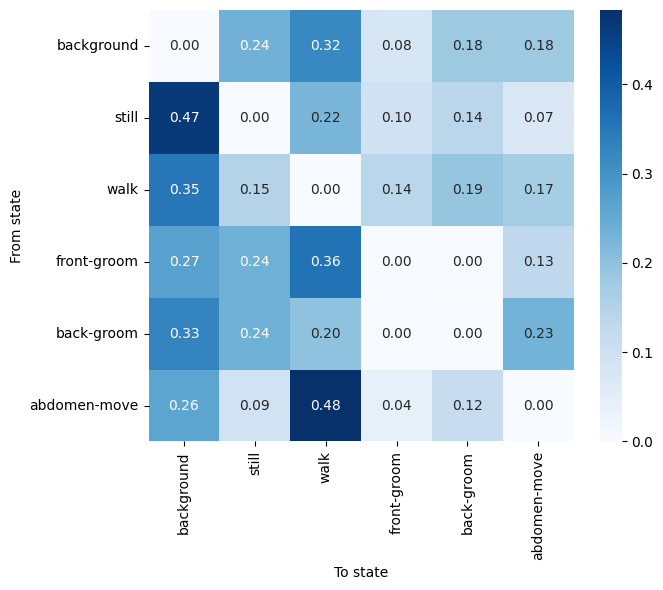

In [9]:
all_freqs = list()

for file_id in file_ids:
	filename, traces, behavior, states, timestamps, aux = analysis_utils.read_data('fly', file_id)

	# 1. Convert one-hot DataFrame to state indices
	state_labels = list(states.columns)
	# background_idx = state_labels.index('background')
	background_idx = np.empty((0,))

	# Convert one-hot to state index
	def onehot_to_index(df):
		return np.argmax(df.values, axis=1)

	state_seq = onehot_to_index(states)

	# 2. Remove 'background' by replacing with most recent non-background state
	state_seq_clean = state_seq.copy()
	N = len(state_seq_clean)

	# Find indices where state is background
	# bg_mask = (state_seq_clean == background_idx)
	bg_mask = np.empty((0,))

	# If the series starts with background, look forward for first non-background
	if False and bg_mask[0]:
		first_non_bg = np.argmax(~bg_mask)
		state_seq_clean[:first_non_bg] = state_seq_clean[first_non_bg]

	# For all other background entries, look back for most recent non-background
	# for i in range(1, N):
	#	 if state_seq_clean[i] == background_idx:
	#		 state_seq_clean[i] = state_seq_clean[i-1]

	# 3. Compute transition matrix (excluding self-transitions)
	num_states = len(state_labels)
	transitions = np.zeros((num_states, num_states), dtype=int)

	for t in range(N-1):
		from_state = state_seq_clean[t]
		to_state = state_seq_clean[t+1]
		if from_state != to_state:
			transitions[from_state, to_state] += 1

	# Remove background row and column for plotting
	# transitions_no_bg = transitions[1:, 1:]
	# labels_no_bg = state_labels[1:]
	transitions_no_bg = transitions
	labels_no_bg = state_labels

	# Normalize to relative frequencies
	row_sums = transitions_no_bg.sum(axis=1, keepdims=True)
	rel_transitions = transitions_no_bg / np.where(row_sums == 0, 1, row_sums)
	
	all_freqs.append(rel_transitions)
	
all_freqs_avg = np.array(all_freqs).mean(axis=0)
	








# 4. Plot heatmap
plt.figure(figsize=(7, 6))
sns.heatmap(
	all_freqs_avg,
	annot=True,
	fmt='.2f',
	cmap='Blues',
	xticklabels=labels_no_bg,
	yticklabels=labels_no_bg
)
plt.xlabel('To state')
plt.ylabel('From state')
plt.title('')
plt.tight_layout()

if save:
	os.makedirs('../../out/plots/state_transitions', exist_ok=True)
	plt.savefig(
		f'../../out/plots/state_transitions/AVERAGE_matrix.png',
		dpi=300,
		bbox_inches='tight'
	)

# plt.clf()
# plt.figure(figsize=(10, 10))
#
# # -----------------------------
# # Build graph
# # -----------------------------
# G = nx.DiGraph()
# G.add_nodes_from(labels_no_bg)
#
# for i, src in enumerate(labels_no_bg):
# 	for j, tgt in enumerate(labels_no_bg):
# 		w = float(rel_transitions[i, j])
# 		if i != j and w > 0:
# 			G.add_edge(src, tgt, weight=w)
#
# # Layout
# pos = nx.spring_layout(G, seed=42, k=2.5)
#
# # Draw nodes
# nx.draw_networkx_nodes(G, pos, node_color='lightblue', node_size=500)
#
# # Draw node labels
# nx.draw_networkx_labels(G, pos, font_size=7)
#
# # Edge labels
# edge_labels = nx.get_edge_attributes(G, 'weight')
# formatted_labels = {edge: f'{label:.2f}' for edge, label in edge_labels.items()}
#
# # Assign unique colors
# import matplotlib.cm as cm
# import matplotlib.colors as mcolors
#
# edge_list = list(G.edges())
# cmap = cm.get_cmap('tab20', len(edge_list))
# edge_colors = {edge: mcolors.to_hex(cmap(i)) for i, edge in enumerate(edge_list)}
#
# # Linewidth scaling
# label_values = np.array(list(edge_labels.values()))
# min_val, max_val = label_values.min(), label_values.max()
# min_width, max_width = 1.0, 6.0
#
# def map_boldness(val):
# 	if max_val == min_val:
# 		return (min_width + max_width) / 2
# 	return min_width + (val - min_val) / (max_val - min_val) * (max_width - min_width)
#
# # Find antiparallel edges
# antiparallel_pairs = set()
# for (u, v) in G.edges():
# 	if (v, u) in G.edges() and (v, u) not in antiparallel_pairs:
# 		antiparallel_pairs.add((u, v))
# 		antiparallel_pairs.add((v, u))
#
# unique_pairs = set()
# for (u, v) in antiparallel_pairs:
# 	if (v, u) in antiparallel_pairs and u < v:
# 		unique_pairs.add((u, v))
#
# # Label placement
# label_offset = 0.15
# for (m, n) in unique_pairs:
# 	x0, y0 = pos[m]
# 	x1, y1 = pos[n]
# 	mx, my = (x0 + x1) / 2, (y0 + y1) / 2
#
# 	dx, dy = x1 - x0, y1 - y0
# 	perp = np.array([-dy, dx])
# 	perp_norm = perp / (np.linalg.norm(perp) + 1e-8)
#
# 	if (m, n) in formatted_labels:
# 		ox, oy = mx - label_offset * perp_norm[0], my - label_offset * perp_norm[1]
# 		plt.text(
# 			ox, oy, formatted_labels[(m, n)],
# 			ha='center', va='center', fontsize=8,
# 			bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
# 			color=edge_colors.get((m, n), 'k')
# 		)
#
# 	if (n, m) in formatted_labels:
# 		ox, oy = mx + label_offset * perp_norm[0], my + label_offset * perp_norm[1]
# 		plt.text(
# 			ox, oy, formatted_labels[(n, m)],
# 			ha='center', va='center', fontsize=8,
# 			bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
# 			color=edge_colors.get((n, m), 'k')
# 		)
#
# # Non-antiparallel edges
# for (u, v), label in formatted_labels.items():
# 	if ((u, v) not in antiparallel_pairs) and ((v, u) not in antiparallel_pairs):
# 		x0, y0 = pos[u]
# 		x1, y1 = pos[v]
# 		mx, my = (x0 + x1) / 2, (y0 + y1) / 2
#
# 		plt.text(
# 			mx, my, label,
# 			ha='center', va='center', fontsize=8,
# 			bbox=dict(facecolor='white', edgecolor='none', alpha=0.7),
# 			color=edge_colors.get((u, v), 'k')
# 		)
#
# # Draw edges
# for (u, v) in edge_list:
# 	lw = map_boldness(G[u][v]['weight'])
# 	color = edge_colors[(u, v)]
#
# 	nx.draw_networkx_edges(
# 		G,
# 		pos,
# 		edgelist=[(u, v)],
# 		connectionstyle='arc3,rad=0.2',
# 		width=lw,
# 		edge_color=color,
# 		alpha=0.7
# 	)
#
# plt.axis('off')
#
# if save:
# 	os.makedirs('../../out/plots/state_transitions', exist_ok=True)
# 	plt.savefig(
# 		f'../../out/plots/state_transitions/{filename}_sequence.png',
# 		dpi=300,
# 		bbox_inches='tight'
# 	)